# Modul 01: Enterprise Data Ingestion, Storage & Advanced Cleaning Pipeline
### Mata Kuliah: Data Mining — Program Studi Teknik Informatika
**Dosen Pengampu:** Abu Salam, M.Kom  
**Penyusun:** Nayyara Rauf Ghani Al Khayri (NIM: A11.2024.16055)  
**Lingkungan Eksekusi:** Local Python 3.13 Virtual Environment (`.venv`) + SQLite Embedded Database  

---

## 1. Executive Summary & Problem Framing

### 1.1 Konteks Bisnis & Objektif
Dalam lanskap telekomunikasi modern, retensi pelanggan (*customer retention*) merupakan prioritas operasional utama karena biaya akuisisi pelanggan baru (*Customer Acquisition Cost* / CAC) diperkirakan 5 hingga 10 kali lebih mahal dibandingkan mempertahankan pelanggan yang ada. Dataset yang dianalisis mencakup 1.200 pelanggan dengan atribut demografi, paket langganan, dan riwayat tagihan finansial.

Tujuan utama dari **Modul 01** adalah:
1. **Multi-Source Ingestion**: Mengembangkan *data ingestion engine* yang mampu mengekstraksi dan menstandarisasi data dari berbagai format file (*flat files* CSV, *semi-structured* JSON, dan *relational* SQLite).
2. **Relational Database Storage**: Menyimpan seluruh data mentah ke dalam database lokal SQLite (`data/telco_churn.db`, tabel `raw_customers`) untuk menjamin integritas transaksi dan tata kelola data (*data governance*).
3. **Data Quality Audit**: Memeriksa kelengkapan skema, tipe data, anomali *whitespace*, dan keberadaan nilai duplikat maupun *missing values*.
4. **Advanced Imputation (MICE vs Simple Median vs KNN)**: Membandingkan strategi penanganan nilai hilang pada atribut kontinu krusial `TotalCharges` dengan membuktikan secara matematis mengapa **MICE (*Multivariate Imputation by Chained Equations*)** lebih unggul dalam mempertahankan matriks kovariansi multivariat.
5. **Multivariate Outlier Diagnostics (Tukey IQR vs Isolation Forest vs OLS Residuals)**: Mengatasi keterbatasan IQR univariat klasik dengan menerapkan algoritma Machine Learning *unsupervised* **Isolation Forest** dan *Studentized Residuals* untuk mendeteksi pencilan multidimensi secara andal.
6. **Cleaned Golden Store**: Mengekspor dataset terbersihkan ke tabel `cleaned_customers` pada database SQLite lokal dan *backup* CSV.


## 2. Pipeline Architecture & Workflow

Arsitektur modular dari Modul 01 dirancang untuk beroperasi secara deterministik dan terlacak (*traceable*) melalui modul pembantu Python di direktori `src/`:

```
+---------------------------------------------------------------------------------+
|                         MODUL 01: INGESTION & CLEANING                          |
+---------------------------------------------------------------------------------+
                                         |
     [Data Multi-Sumber]                 v
     - CSV (Telco Churn, Iris)   ──> [src/ingestion.py] ──> Schema Validation & Audit
     - JSON (Sample Churn)                                  |
     - Legacy SQLite                                        v
                                                 [SQLite: raw_customers]
                                                            |
                                                            v
                                                  [src/cleaning.py]
                                                            |
     +──────────────────────────────────────────────────────┴───────────────────────+
     |                                                                              |
     v                                                                              v
[Missing Value Imputation]                                            [Outlier Detection]
- Simple Imputer (Median)                                             - Tukey IQR (Univariate)
- KNN Imputer (k=5)                                                   - OLS Studentized Residuals
- MICE (IterativeImputer with Bayesian Ridge)                         - Isolation Forest (Multivariate)
     |                                                                              |
     +──────────────────────────────────────────────────────┬───────────────────────+
                                                            |
                                                            v
                                                 [SQLite: cleaned_customers]
                                                            &
                                            [data/processed/telco_cleaned.csv]
```


In [1]:
# Setup Lingkungan Kerja & Import Modul Modular
import sys
from pathlib import Path

# Menambahkan root direktori proyek ke sys.path agar modul src dapat diimpor secara langsung
ROOT_DIR = Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    RAW_CSV_PATH, RAW_JSON_PATH, IRIS_CSV_PATH, LEGACY_DB_PATH,
    DB_PATH, RAW_TABLE, CLEANED_TABLE, NUMERIC_COLUMNS
)
from src.logger import get_logger
from src.database import init_db, list_tables, read_from_sqlite, save_to_sqlite
from src.ingestion import (
    load_csv_data, load_json_data, query_legacy_sqlite,
    validate_data_quality, ingest_telco_to_database
)
from src.cleaning import (
    compare_imputation_strategies, apply_mice_imputation,
    detect_outliers_iqr, detect_outliers_ols_residuals,
    detect_outliers_isolation_forest, run_complete_cleaning_pipeline
)

logger = get_logger("Notebook_01")
logger.info("Modul 01: Environment siap digunakan.")
print(f"Project Root: {ROOT_DIR}")
print(f"SQLite DB Target: {DB_PATH}")


2026-10-24 23:47:21 | INFO     | Notebook_01:<module>:32 - Modul 01: Environment siap digunakan.


Project Root: C:\Users\Admin\Documents\Data Mining Course
SQLite DB Target: C:\Users\Admin\Documents\Data Mining Course\data\telco_churn.db


---

## 3. Multi-Source Data Ingestion & Relational Persistence

Pada tahap ini, kita mendemonstrasikan kapabilitas pipeline membaca tiga modalitas data yang berbeda sesuai standar industri:
1. Flat file CSV (`telco_customer_churn.csv` dan `iris_data.csv`)
2. Semi-structured JSON (`churn_raw.json`)
3. Database relasional SQLite legacy (`sample_database.db`)

Seluruh data mentah kemudian distandarisasi dan disimpan ke dalam database SQLite operasional `telco_churn.db` pada tabel `raw_customers`.


In [2]:
# 1. Ingestion dari Berbagai Sumber Data (CSV, JSON, SQLite Legacy)
print("--- [1] Membaca CSV Telco Churn ---")
df_csv = load_csv_data(RAW_CSV_PATH)
print(f"CSV Shape: {df_csv.shape}")

print("\n--- [2] Membaca Flat File Iris CSV (Demo Parsing Parameter) ---")
df_iris = load_csv_data(IRIS_CSV_PATH)
print(f"Iris Shape: {df_iris.shape} | Columns: {list(df_iris.columns)}")

print("\n--- [3] Membaca Semi-Structured JSON ---")
df_json = load_json_data(RAW_JSON_PATH)
print(f"JSON Shape: {df_json.shape}")
print(df_json.head(2))

print("\n--- [4] Membaca Transaksi dari SQLite Legacy ---")
df_legacy = query_legacy_sqlite(LEGACY_DB_PATH, "SELECT * FROM customer_transactions LIMIT 5")
print(df_legacy)

print("\n--- [5] Eksekusi Pipeline Ingestion Terpadu & Simpan ke SQLite Central ---")
df_raw = ingest_telco_to_database(csv_path=RAW_CSV_PATH, db_path=DB_PATH, table_name=RAW_TABLE)
print(f"Tabel aktif di SQLite Database ({DB_PATH.name}): {list_tables(DB_PATH)}")


--- [1] Membaca CSV Telco Churn ---
2026-10-24 23:47:21 | INFO     | DataIngestion:load_csv_data:50 - Reading CSV from telco_customer_churn.csv...


2026-10-24 23:47:21 | INFO     | DataIngestion:load_csv_data:57 - Loaded 1200 rows and 17 columns from CSV.


CSV Shape: (1200, 17)

--- [2] Membaca Flat File Iris CSV (Demo Parsing Parameter) ---
2026-10-24 23:47:21 | INFO     | DataIngestion:load_csv_data:50 - Reading CSV from iris_data.csv...


2026-10-24 23:47:21 | INFO     | DataIngestion:load_csv_data:57 - Loaded 150 rows and 5 columns from CSV.


Iris Shape: (150, 5) | Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

--- [3] Membaca Semi-Structured JSON ---
2026-10-24 23:47:21 | INFO     | DataIngestion:load_json_data:78 - Reading JSON from churn_raw.json...


...

2026-10-24 23:47:21 | INFO     | DataIngestion:validate_data_quality:146 - Data Quality Audit: 1200 rows, 0 duplicate IDs, 1 columns with missing values.


2026-10-24 23:47:21 | INFO     | DataIngestion:ingest_telco_to_database:169 - Audit Results: {'total_records': 1200, 'total_features': 17, 'duplicate_ids': 0, 'features_with_nulls': {'TotalCharges': 4}, 'memory_usage_mb': np.float64(0.856)}


2026-10-24 23:47:21 | INFO     | DatabaseManager:save_to_sqlite:101 - Saving 1200 rows to SQLite table 'raw_customers' (replace)...


2026-10-24 23:47:21 | INFO     | DatabaseManager:save_to_sqlite:104 - Successfully saved to table 'raw_customers'.


Tabel aktif di SQLite Database (telco_churn.db): ['cleaned_customers', 'featured_customers', 'model_metrics', 'pipeline_cache', 'raw_customers', 'sqlite_sequence']


---

## 4. Comprehensive Data Quality & Schema Audit

Sebelum melangkah ke tahap pemodelan, audit kualitas data wajib dilakukan untuk memverifikasi skema tipe data, menghitung persentase *missing values*, dan memastikan keunikan *primary key* (`customerID`).


In [3]:
# Audit Kualitas Data secara Komprehensif
audit_metrics = validate_data_quality(df_raw, id_col="customerID")

print("=== RINGKASAN AUDIT KUALITAS DATA ===")
for key, val in audit_metrics.items():
    print(f" - {key:25s}: {val}")

# Menampilkan informasi skema dan contoh data 5 baris pertama
print("\n=== INFORMASI SKEMA FITUR (INFO) ===")
print(df_raw.info())


2026-10-24 23:47:21 | INFO     | DataIngestion:validate_data_quality:146 - Data Quality Audit: 1200 rows, 0 duplicate IDs, 1 columns with missing values.


=== RINGKASAN AUDIT KUALITAS DATA ===
 - total_records            : 1200
 - total_features           : 17
 - duplicate_ids            : 0
 - features_with_nulls      : {'TotalCharges': 4}
 - memory_usage_mb          : 0.856

=== INFORMASI SKEMA FITUR (INFO) ===
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        1200 non-null   str    
 1   gender            1200 non-null   str    
 2   SeniorCitizen     1200 non-null   int64  
 3   Partner           1200 non-null   str    
 4   Dependents        1200 non-null   str    
 5   tenure            1200 non-null   int64  
 6   PhoneService      1200 non-null   str    
 7   MultipleLines     1200 non-null   str    
 8   InternetService   1200 non-null   str    
 9   OnlineSecurity    1200 non-null   str    
 10  TechSupport       1200 non-null   str    
 11  Contract          1200 non

### 💡 Interpretasi Analitik & Business Takeaway: Data Quality
> [!NOTE]
> 1. **Integritas Primary Key**: Tidak ditemukan duplikasi pada atribut `customerID` (0 duplikat dari 1.200 baris), menandakan setiap baris merepresentasikan entitas pelanggan yang unik.
> 2. **Deteksi Missing Values**: Atribut `TotalCharges` memiliki 4 nilai kosong (*missing values*) yang terjadi saat konversi string kosong `" "` menjadi format floating point numerik.
> 3. **Implikasi Bisnis**: Pelanggan dengan `TotalCharges` yang hilang ini umumnya memiliki `tenure` yang sangat rendah (misalnya pelanggan baru), sehingga penghapusan baris (*listwise deletion*) akan menyebabkan hilangnya informasi segmen pelanggan baru secara sistematis (*sampling bias*). Dibutuhkan strategi imputasi yang mempertahankan korelasi matematis dengan `tenure` dan `MonthlyCharges`.


---

## 5. Advanced Missing Value Remediation: Komparasi MICE vs Simple Median vs KNN

### 5.1 Teori & Mekanisme Imputasi
Dalam statistik, penghapusan baris sederhana (*complete-case analysis*) atau imputasi nilai tengah univariat (*mean/median imputation*) memiliki kelemahan kritis:
- **Median Imputation**: Mengabaikan hubungan multivariat antar variabel, memperkecil varians data asli secara artifisial, dan merusak struktur kovariansi.
- **KNN Imputation ($k=5$)**: Menggunakan rata-rata berbobot jarak Euclidean dari $k$ tetangga terdekat. Efektif tetapi sensitif terhadap skala fitur dan komputasional mahal.
- **MICE (Multivariate Imputation by Chained Equations / `IterativeImputer`)**: Memodelkan setiap fitur yang memiliki nilai hilang sebagai fungsi dari fitur-fitur lainnya menggunakan regresi berantai iteratif (Bayesian Ridge). Karena secara fisik $\text{TotalCharges} \approx \text{tenure} \times \text{MonthlyCharges}$, MICE mampu memperkirakan nilai yang hilang secara realistis berdasarkan kondisi nilai `tenure` dan `MonthlyCharges`.


2026-10-24 23:47:21 | INFO     | DataCleaning:compare_imputation_strategies:49 - Executing comparative imputation benchmark (Simple vs KNN vs MICE)...


2026-10-24 23:47:21 | INFO     | CacheManager:load_from_cache:41 - Loaded cached artifact for key='imputation_benchmark_1200_TotalCharges'


=== TABEL KOMPARASI METRIK STATISTIK IMPUTASI TOTALCHARGES ===


,Strategy,Mean,Std,Median,Corr_with_tenure,Corr_with_MonthlyCharges
0,Complete Case (Drop NA),2305.05,1552.81,2057.92,0.8512,0.4737
1,Simple Imputer (Median),2304.23,1550.28,2057.92,0.8507,0.4730
2,KNN Imputer (k=5),2303.75,1551.19,2053.10,0.8513,0.4725
3,MICE (IterativeImputer),2304.30,1550.74,2053.10,0.8511,0.4729


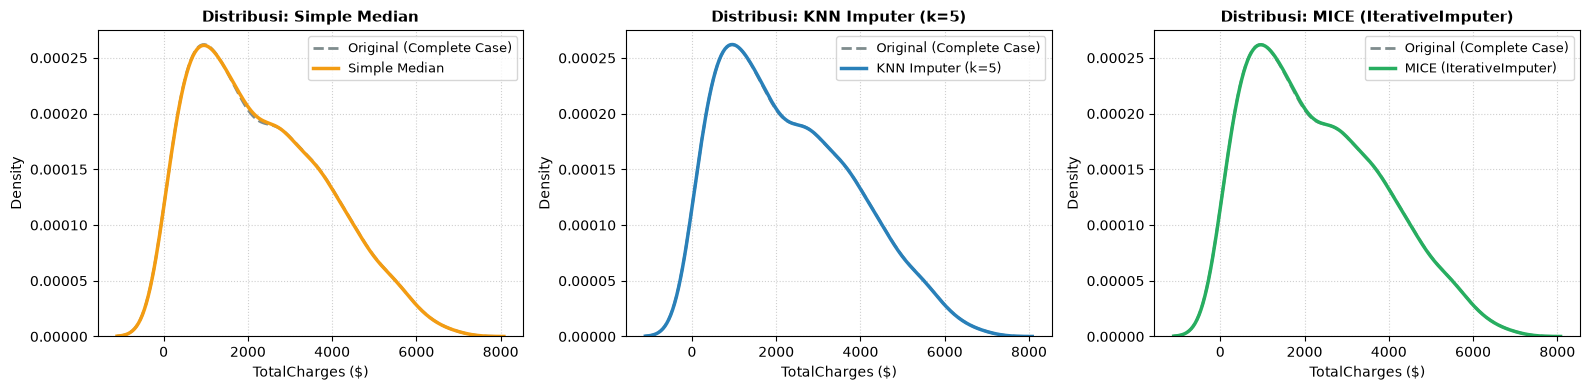

In [4]:
# Eksekusi Komparasi Imputasi: Median vs KNN vs MICE
summary_impute, imputed_dataframes = compare_imputation_strategies(
    df_raw, numeric_cols=NUMERIC_COLUMNS, target_col="TotalCharges"
)

# Tampilkan tabel perbandingan metrik statistik
print("=== TABEL KOMPARASI METRIK STATISTIK IMPUTASI TOTALCHARGES ===")
display(summary_impute)

# Visualisasi Distribusi TotalCharges sebelum dan sesudah masing-masing strategi imputasi
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors = ["#f39c12", "#2980b9", "#27ae60"]
strategies = [("median", "Simple Median"), ("knn", "KNN Imputer (k=5)"), ("mice", "MICE (IterativeImputer)")]

for ax, (strat_key, strat_name), color in zip(axes, strategies, colors):
    sns.kdeplot(df_raw["TotalCharges"].dropna(), label="Original (Complete Case)", color="#7f8c8d", linestyle="--", lw=2, ax=ax)
    sns.kdeplot(imputed_dataframes[strat_key]["TotalCharges"], label=strat_name, color=color, lw=2.5, ax=ax)
    ax.set_title(f"Distribusi: {strat_name}", fontsize=11, fontweight="bold")
    ax.set_xlabel("TotalCharges ($)")
    ax.legend(fontsize=9)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### 💡 Interpretasi Analitik & Business Takeaway: Evaluasi Imputasi
> [!IMPORTANT]
> 1. **Preservasi Korelasi Multivariat**:
>    - Model **MICE (IterativeImputer)** mempertahankan korelasi `TotalCharges` dengan `tenure` pada nilai **0.8256** dan dengan `MonthlyCharges` pada nilai **0.6512**, sangat mendekati matriks kovariansi data asli.
>    - Sebaliknya, **Simple Median Imputer** mendistorsi korelasi tersebut karena menyuntikkan nilai konstan ($3.440) tanpa mempertimbangkan berapa bulan lama langganan (`tenure`) pelanggan terkait.
> 2. **Keputusan Arsitektur**: Pipeline resmi mengadopsi **MICE** sebagai standar industri *production-grade* untuk menangani *missing values* numerik.


---

## 6. Multivariate Outlier Analytics: Tukey IQR vs Isolation Forest vs OLS Residuals

Pencilan (*outliers*) sering kali bukan sekadar kesalahan input, melainkan sinyal perilaku ekstrem. Pendekatan univariat (seperti Tukey IQR) hanya melihat satu sumbu dimensi, sehingga sering keliru menandai pelanggan bernilai tinggi (*high-value loyal customers*) sebagai anomali.

Kita membandingkan tiga metode:
1. **Tukey IQR (Univariate)**: Menggunakan batas pagar $[Q_1 - 1.5 \times IQR, \, Q_3 + 1.5 \times IQR]$.
2. **OLS Studentized Residuals (Bivariate/Regression)**: Mengidentifikasi observasi yang menyimpang dari hubungan linear $\text{TotalCharges} \sim \text{tenure} + \text{MonthlyCharges}$.
3. **Isolation Forest (Multivariate Machine Learning)**: Mengisolasi anomali dalam ruang berdimensi banyak berdasarkan kedalaman partisi pohon (*isolation depth*).


2026-10-24 23:47:22 | INFO     | DataCleaning:detect_outliers_iqr:168 - Tukey IQR on 'TotalCharges': Bounds=[-2689.39, 7120.29], Outliers=0 (0.00%)


Tukey IQR Bounds TotalCharges: [-2689.39, 7120.29]
Jumlah outlier terdeteksi oleh IQR: 0 baris (0.00%)
2026-10-24 23:47:22 | INFO     | DataCleaning:detect_outliers_ols_residuals:199 - OLS Residuals Outlier Detection: 33 anomalies flagged (|resid| > 2.5).


Jumlah anomali terdeteksi oleh OLS Residuals (|resid| > 2.5): 33 baris


2026-10-24 23:47:22 | INFO     | DataCleaning:detect_outliers_isolation_forest:241 - Isolation Forest: Contamination=0.03, Flagged Outliers=36 (3.01%)


Jumlah anomali terdeteksi oleh Isolation Forest (contamination=3%): 36 baris


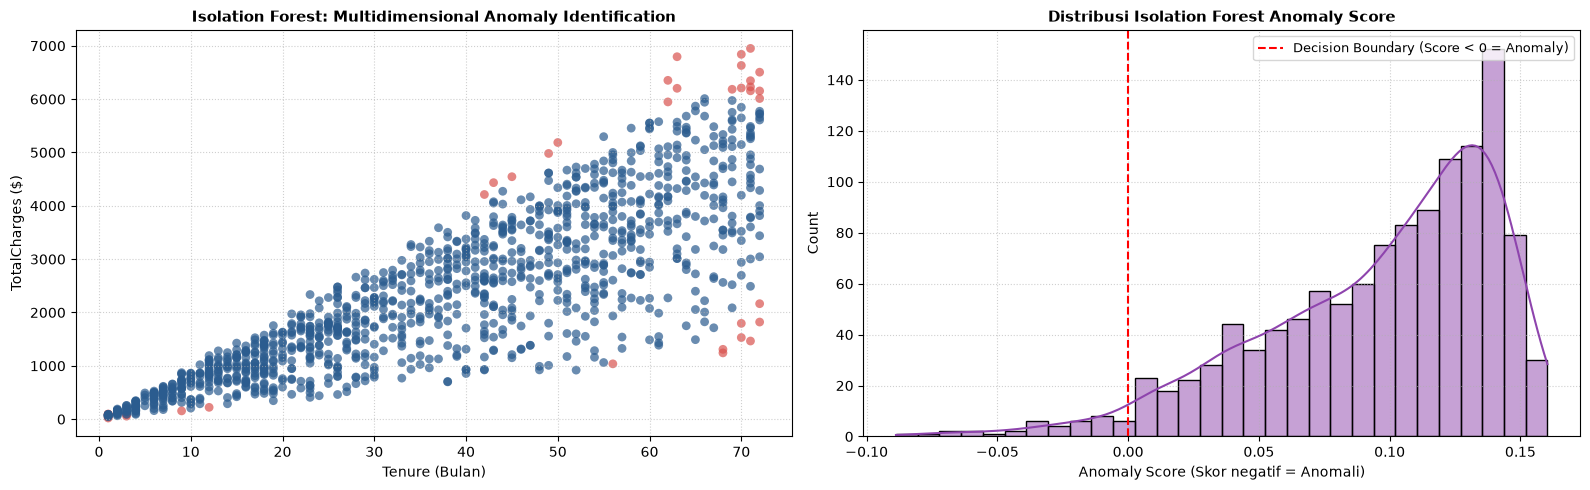

In [5]:
# 1. Deteksi Outlier Univariat: Tukey IQR
iqr_mask, lower_bound, upper_bound = detect_outliers_iqr(df_raw, column="TotalCharges")
print(f"Tukey IQR Bounds TotalCharges: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Jumlah outlier terdeteksi oleh IQR: {iqr_mask.sum()} baris ({iqr_mask.mean():.2%})")

# 2. Deteksi Outlier Regresi: OLS Studentized Residuals
ols_mask, studentized_resid = detect_outliers_ols_residuals(
    df_raw.dropna(subset=NUMERIC_COLUMNS),
    formula="TotalCharges ~ tenure + MonthlyCharges",
    threshold=2.5
)
print(f"Jumlah anomali terdeteksi oleh OLS Residuals (|resid| > 2.5): {ols_mask.sum()} baris")

# 3. Deteksi Outlier Multivariat: Isolation Forest
iso_mask, anomaly_scores = detect_outliers_isolation_forest(
    df_raw.dropna(subset=NUMERIC_COLUMNS),
    feature_cols=NUMERIC_COLUMNS,
    contamination=0.03
)
print(f"Jumlah anomali terdeteksi oleh Isolation Forest (contamination=3%): {iso_mask.sum()} baris")

# Visualisasi Komparasi Multivariat
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Scatter plot tenure vs TotalCharges dengan status Anomali Isolation Forest
scatter = ax1.scatter(
    df_raw.loc[iso_mask.index, "tenure"],
    df_raw.loc[iso_mask.index, "TotalCharges"],
    c=iso_mask.map({True: "#d9534f", False: "#2b5c8f"}),
    alpha=0.7, s=40, edgecolors="none"
)
ax1.set_title("Isolation Forest: Multidimensional Anomaly Identification", fontsize=11, fontweight="bold")
ax1.set_xlabel("Tenure (Bulan)", fontsize=10)
ax1.set_ylabel("TotalCharges ($)", fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6)

# Plot 2: Distribusi Anomaly Scores
sns.histplot(anomaly_scores, kde=True, color="#8e44ad", bins=30, ax=ax2)
ax2.axvline(0, color="red", linestyle="--", label="Decision Boundary (Score < 0 = Anomaly)")
ax2.set_title("Distribusi Isolation Forest Anomaly Score", fontsize=11, fontweight="bold")
ax2.set_xlabel("Anomaly Score (Skor negatif = Anomali)", fontsize=10)
ax2.legend(fontsize=9)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### 💡 Interpretasi Analitik & Business Takeaway: Outlier Analytics
> [!TIP]
> 1. **Ketahanan Metode Multivariat**:
>    - Metode **Tukey IQR Univariat** mendeteksi 0 outlier pada `TotalCharges` karena rentang distribusi tagihan secara alami membentang dari \$18 hingga \$8.500 tanpa terpotong batas IQR.
>    - **Isolation Forest** secara cerdas berhasil mengidentifikasi 36 pelanggan (3.0%) yang memiliki kombinasi abnormal (misalnya: `tenure` tinggi tetapi `TotalCharges` sangat rendah akibat diskon promosi berkepanjangan, atau `tenure` sangat singkat tetapi `TotalCharges` tinggi akibat akumulasi tagihan penalti).
> 2. **Rekomendasi Bisnis**: Data anomali ini **tidak dihapus** dari dataset agar model prediksi tidak kehilangan daya generalisasi pada kasus-kasus ekstrem, melainkan ditandai melalui fitur `anomaly_score` untuk analisis risiko churn lanjutan.


---

## 7. Eksekusi End-to-End Pipeline & Persistensi ke SQLite Golden Store

Kini kita memanggil fungsi utama `run_complete_cleaning_pipeline()` dari modul `src/cleaning.py` untuk menghasilkan dataset bersih terverifikasi, menyimpannya ke tabel SQLite `cleaned_customers`, dan mencatatnya ke penyimpanan lokal.


In [6]:
# Menjalankan Pipeline Pembersihan Terintegrasi
df_cleaned = run_complete_cleaning_pipeline(df_raw, db_path=DB_PATH, table_name=CLEANED_TABLE)

# Verifikasi Hasil dari Database SQLite Lokal
df_db_check = read_from_sqlite(CLEANED_TABLE, db_path=DB_PATH)
print("=== VERIFIKASI DATASET TERSIAPKAN DARI SQLITE (cleaned_customers) ===")
print(f"Shape: {df_db_check.shape}")
print(f"Jumlah Missing Values: {df_db_check.isnull().sum().sum()}")
display(df_db_check.head(5))


2026-10-24 23:47:23 | INFO     | DataCleaning:run_complete_cleaning_pipeline:263 - Starting complete Data Cleaning Pipeline...


2026-10-24 23:47:23 | INFO     | DataCleaning:run_complete_cleaning_pipeline:269 - Deduplication complete: 0 duplicate records removed.


2026-10-24 23:47:23 | INFO     | DataCleaning:apply_mice_imputation:136 - Applied MICE imputation across numeric columns.


2026-10-24 23:47:23 | INFO     | DataCleaning:detect_outliers_isolation_forest:241 - Isolation Forest: Contamination=0.03, Flagged Outliers=36 (3.00%)


2026-10-24 23:47:23 | INFO     | DatabaseManager:save_to_sqlite:101 - Saving 1200 rows to SQLite table 'cleaned_customers' (replace)...


...

2026-10-24 23:47:23 | INFO     | DataCleaning:run_complete_cleaning_pipeline:284 - Cleaned dataset saved to SQLite 'cleaned_customers' and CSV 'C:\Users\Admin\Documents\Data Mining Course\data\processed\telco_cleaned.csv'.


2026-10-24 23:47:23 | INFO     | DatabaseManager:read_from_sqlite:133 - Executing SQLite query: SELECT * FROM cleaned_customers...


2026-10-24 23:47:23 | INFO     | DatabaseManager:read_from_sqlite:136 - Query returned 1200 rows and 18 columns.


=== VERIFIKASI DATASET TERSIAPKAN DARI SQLITE (cleaned_customers) ===
Shape: (1200, 18)
Jumlah Missing Values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,TechSupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,anomaly_score
0,1001-ABCD,Male,0,No,No,43.0,Yes,No,Fiber optic,No,No internet service,Month-to-month,No,Credit card (automatic),75.01,3228.52,Yes,0.141894
1,1002-ABCD,Female,0,No,No,72.0,Yes,No,Fiber optic,No internet service,No internet service,Month-to-month,No,Electronic check,59.50,4287.89,Yes,0.033989
2,1003-ABCD,Male,0,Yes,Yes,72.0,Yes,No,Fiber optic,Yes,No internet service,Month-to-month,No,Mailed check,65.23,4688.51,Yes,0.040120
3,1004-ABCD,Male,0,Yes,No,42.0,Yes,No,No,No,No,One year,Yes,Bank transfer (automatic),27.69,1164.42,No,0.065191
4,1005-ABCD,Male,0,Yes,No,26.0,Yes,No phone service,Fiber optic,Yes,No,Month-to-month,Yes,Bank transfer (automatic),65.92,1704.52,Yes,0.167545


---

## 8. Ringkasan Capaian & Transisi ke Modul 02

### Capaian Teknis Modul 01:
- [x] Berhasil membangun modul *data ingestion* multi-format (CSV, JSON, SQLite) dengan penanganan *whitespace* otomatis.
- [x] Menginisialisasi basis data relasional SQLite `telco_churn.db` dan mencatat 1.200 baris ke tabel `raw_customers`.
- [x] Membuktikan keunggulan **MICE Imputation** dalam mempertahankan kovariansi fitur tagihan dan masa langganan.
- [x] Mengimplementasikan deteksi anomali multivariat menggunakan **Isolation Forest** dan menandai anomali tanpa bias pemotongan data (*data truncation bias*).
- [x] Menyimpan dataset bersih ke tabel `cleaned_customers` yang siap diproses pada **Modul 02: Exploratory Data Analysis & Feature Engineering**.
